# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

- **Trạng thái ban đầu:** bàn có kích thước cố định, `lines={}`, `boxes={}`; chưa có ô nào được sở hữu và người chơi +1 đi trước.
- **Actions(s):** mọi cạnh ngang/dọc hợp lệ chưa được vẽ.
- **Transition:** thêm cạnh vào `lines`; với mỗi ô kề cạnh, nếu đủ bốn cạnh thì ghi `boxes[(r,c)] = player`. Nếu nước đi hoàn thành ít nhất một ô, người chơi vừa đi được đi tiếp; nếu không thì đổi lượt.
- **Terminal(s):** không còn cạnh hợp lệ.
- **Utility(s):** ở trạng thái kết thúc, số ô của người chơi đang xét trừ số ô của đối thủ.

Với R×C điểm, số cạnh là E = R(C−1)+(R−1)C và số ô là B=(R−1)(C−1). Có `2^E` **cấu hình có/không của các cạnh**. Tuy nhiên, `2^E` không phải số trạng thái đầy đủ của trò chơi: cùng một tập cạnh đã vẽ có thể dẫn đến chủ sở hữu ô và người đang đi khác nhau tùy thứ tự vẽ cạnh. Với cách mã hóa hiện tại, một cận trên rất lỏng cho số bộ mã hóa `(cấu hình cạnh, chủ sở hữu mỗi ô, người chơi hiện tại)` là `2 × 2^E × 3^B`; nhiều bộ trong cận này không thể xảy ra trong trò chơi.

Cây trò chơi đếm cả thứ tự đặt cạnh. Với E cạnh, số chuỗi nước đi tiền tố không lặp cạnh được chặn trên bởi `Σ P(E,k)`, k=0..E. Đây là cận rất lỏng; mỗi nhánh thực tế dừng khi không còn cạnh, và alpha-beta cùng move ordering có thể giảm số nút phải duyệt.

In [75]:
import pandas as pd
from IPython.display import display


# Task 1 — Các thành phần của bài toán tìm kiếm
components = {
    "Initial state": "Bàn chưa có cạnh nào; chưa có ô nào được sở hữu.",
    "Actions(s)": "Mọi cạnh ngang/dọc hợp lệ chưa được vẽ.",
    "Transition model": "Thêm cạnh; nếu một ô đủ bốn cạnh thì gán ô cho người vừa vẽ cạnh.",
    "Terminal test": "Không còn cạnh hợp lệ để vẽ.",
    "Utility": "Ở trạng thái kết thúc: số ô của người chơi trừ số ô của đối thủ."
}
display(pd.DataFrame([{"Thành phần":k,"Định nghĩa":v} for k,v in components.items()]))
import os

# Tạo thư mục result tại thư mục đang chạy notebook
RESULT_DIR = "result"
os.makedirs(RESULT_DIR, exist_ok=True)

print(f"Thư mục lưu kết quả: {os.path.abspath(RESULT_DIR)}")


,Thành phần,Định nghĩa
0,Initial state,Bàn chưa có cạnh nào; chưa có ô nào được sở hữu.
1,Actions(s),Mọi cạnh ngang/dọc hợp lệ chưa được vẽ.
2,Transition model,Thêm cạnh; nếu một ô đủ bốn cạnh thì gán ô cho...
3,Terminal test,Không còn cạnh hợp lệ để vẽ.
4,Utility,Ở trạng thái kết thúc: số ô của người chơi trừ...


Thư mục lưu kết quả: f:\TTNTNC\LAB05_GAME\result


How big is the state space? Give an estimate and explain it.

In [76]:

# Ước lượng không gian trạng thái
def edge_count(size):
    R,C=size
    return R*(C-1)+(R-1)*C

R=C=4  # cấu hình minh họa 4x4 điểm của notebook
E=edge_count((R,C))
print(f"Với {R}x{C} điểm: E = {R}({C}-1)+({R}-1){C} = {E} cạnh.")
print(f"Mỗi cạnh có 2 trạng thái (đã vẽ/chưa vẽ), nên cận trên không gian trạng thái là 2^{E:,} = {2**E:,}.")
print("Đây là cận trên theo tập cạnh; trạng thái có thêm thông tin chủ sở hữu ô và lượt đi, nhưng các thông tin này được suy ra từ lịch sử nước đi.")


Với 4x4 điểm: E = 4(4-1)+(4-1)4 = 24 cạnh.
Mỗi cạnh có 2 trạng thái (đã vẽ/chưa vẽ), nên cận trên không gian trạng thái là 2^24 = 16,777,216.
Đây là cận trên theo tập cạnh; trạng thái có thêm thông tin chủ sở hữu ô và lượt đi, nhưng các thông tin này được suy ra từ lịch sử nước đi.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [77]:

# Ước lượng kích thước game tree
import math
E=edge_count((4,4))
# Cận trên: mọi chuỗi nước đi hợp lệ có độ dài 0..E, không lặp cạnh.
tree_bound=sum(math.factorial(E)//math.factorial(E-k) for k in range(E+1))
print(f"Với E={E} cạnh, số chuỗi nước đi tối đa được chặn trên bởi Σ P(E,k), k=0..E.")
print(f"Cận trên xấp xỉ: {tree_bound:.4e} nút lịch sử.")
print("Đây là cận rất lỏng vì game kết thúc sau khi mọi cạnh được vẽ và việc ăn ô giữ lượt; alpha-beta cùng move ordering giúp tránh duyệt toàn bộ cây.")


Với E=24 cạnh, số chuỗi nước đi tối đa được chặn trên bởi Σ P(E,k), k=0..E.
Cận trên xấp xỉ: 1.6866e+24 nút lịch sử.
Đây là cận rất lỏng vì game kết thúc sau khi mọi cạnh được vẽ và việc ăn ô giữ lượt; alpha-beta cùng move ordering giúp tránh duyệt toàn bộ cây.


## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [78]:

import math, time, random, os
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def new_board(size=(3,3)):
    """size = (number of dot rows, number of dot columns)."""
    return {"size":tuple(size),"lines":{},"boxes":{}}

def all_actions(s):
    R,C=s["size"]
    return ([('h',r,c) for r in range(R) for c in range(C-1)] +
            [('v',r,c) for r in range(R-1) for c in range(C)])

def box_edges(r,c):
    return {('h',r,c),('h',r+1,c),('v',r,c),('v',r,c+1)}

def actions(s):
    return [a for a in all_actions(s) if a not in s["lines"]]

def adjacent_boxes(a):
    o,r,c=a
    if o=='h': return [(r-1,c),(r,c)]
    return [(r,c-1),(r,c)]

def result(s,a,player):
    if a not in actions(s): raise ValueError(f"Illegal action: {a}")
    ns={"size":s["size"],"lines":dict(s["lines"]),"boxes":dict(s["boxes"])}
    ns["lines"][a]=True
    for box in adjacent_boxes(a):
        r,c=box
        if 0<=r<ns["size"][0]-1 and 0<=c<ns["size"][1]-1 and box not in ns["boxes"]:
            if box_edges(r,c).issubset(ns["lines"].keys()):
                ns["boxes"][box]=int(player)
    return ns

def captured(s,a,player):
    ns=result(s,a,player)
    return len(ns["boxes"])>len(s["boxes"])

def next_player(s,ns,player):
    return player if len(ns["boxes"])>len(s["boxes"]) else -player

def terminal(s):
    return len(actions(s))==0

def utility(s,player=1):
    if not terminal(s): return None
    return sum(v for v in s["boxes"].values())*int(player)

def score(s,player):
    return sum(v==player for v in s["boxes"].values()),sum(v==-player for v in s["boxes"].values())

def draw_board(s,ax=None):
    R,C=s["size"]
    if ax is None: fig,ax=plt.subplots(figsize=(max(4,C),max(3,R)))
    ax.set_xlim(-.25,C-.75); ax.set_ylim(R-.75,-.25); ax.set_aspect('equal'); ax.axis('off')
    for r in range(R):
        for c in range(C):
            ax.plot(c,r,'ko',ms=5)
    for (o,r,c) in s["lines"]:
        if o=='h': ax.plot([c,c+1],[r,r],lw=3,solid_capstyle='round')
        else: ax.plot([c,c],[r,r+1],lw=3,solid_capstyle='round')
    for (r,c),p in s["boxes"].items():
        ax.text(c+.5,r+.5,'X' if p==1 else 'O',ha='center',va='center',fontsize=18)
    return ax

def random_player(s,player=1):
    return random.choice(actions(s))

def play_game(agent1,agent2,size=(3,3),seed=None):
    if seed is not None: random.seed(seed)
    s=new_board(size); p=1
    while not terminal(s):
        agent=agent1 if p==1 else agent2
        a=agent(s,p)
        ns=result(s,a,p)
        p=next_player(s,ns,p); s=ns
    x,o=score(s,1)
    return (1 if x>o else -1 if o>x else 0),s

def random_tournament(n=1000,size=(3,3),seed=2026):
    counts=Counter()
    for i in range(n):
        w,_=play_game(random_player,random_player,size,seed+i)
        counts[w]+=1
    return {"Player +1 wins":counts[1],"Player -1 wins":counts[-1],"Draws":counts[0],"Games":n}

def immediate_capture(s,a,p):
    return captured(s,a,p)

def creates_third_side(s,a,p):
    # A non-capturing move that leaves an unclaimed box with exactly three edges.
    ns=result(s,a,p)
    for (r,c) in adjacent_boxes(a):
        if 0<=r<ns["size"][0]-1 and 0<=c<ns["size"][1]-1:
            if (r,c) not in ns["boxes"] and len(box_edges(r,c)&ns["lines"].keys())==3:
                return True
    return False

def ordered_actions(s,p,ordering=True):
    acts=actions(s)
    if not ordering: return acts
    # captures first, safe moves next, moves gifting a 3rd edge last
    return sorted(acts,key=lambda a:(0 if immediate_capture(s,a,p) else 2 if creates_third_side(s,a,p) else 1))

def heuristic(s,root_player,to_move):
    diff=sum(v==root_player for v in s["boxes"].values())-sum(v==-root_player for v in s["boxes"].values())
    if terminal(s): return float(diff)
    # Small tempo-aware term: a 3-sided unclaimed box is an immediate capture for side to move.
    urgent=sum(1 for (r,c) in [(r,c) for r in range(s["size"][0]-1) for c in range(s["size"][1]-1)]
               if (r,c) not in s["boxes"] and len(box_edges(r,c)&s["lines"].keys())==3)
    return float(diff + (0.20*urgent if to_move==root_player else -0.20*urgent))

def minimax_alpha_beta(s,player=1,depth=None,move_ordering=True):
    stats={"nodes":0,"leaves":0,"prunes":0}
    root=player
    def rec(state,to_move,d,alpha,beta):
        stats["nodes"]+=1
        if terminal(state):
            stats["leaves"]+=1
            return float(utility(state,root)),None
        if depth is not None and d>=depth:
            stats["leaves"]+=1
            return heuristic(state,root,to_move),None
        maximizing=(to_move==root)
        best=-math.inf if maximizing else math.inf
        best_a=None
        for a in ordered_actions(state,to_move,move_ordering):
            ns=result(state,a,to_move); np_=next_player(state,ns,to_move)
            val,_=rec(ns,np_,d+1,alpha,beta)
            if maximizing and val>best: best,best_a=val,a
            if not maximizing and val<best: best,best_a=val,a
            if maximizing: alpha=max(alpha,best)
            else: beta=min(beta,best)
            if alpha>=beta:
                stats["prunes"]+=1; break
        return best,best_a
    value,move=rec(s,player,0,-math.inf,math.inf)
    return {"move":move,"value":value,**stats}

def minimax_player(s,player=1):
    return minimax_alpha_beta(s,player,depth=None)["move"]

def heuristic_player(depth=5):
    def agent(s,player=1): return minimax_alpha_beta(s,player,depth=depth)["move"]
    return agent


Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

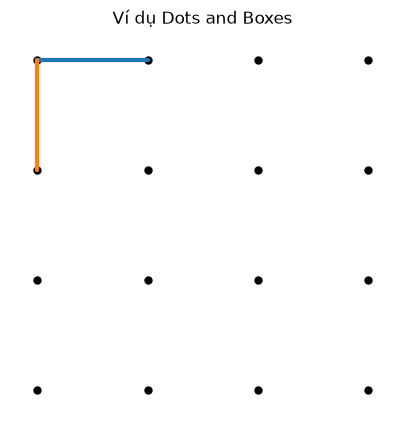

In [79]:

board=new_board((4,4))
board=result(board,('h',0,0),1)
board=result(board,('v',0,0),-1)
fig,ax=plt.subplots(figsize=(5,5)); draw_board(board,ax); ax.set_title("Ví dụ Dots and Boxes"); plt.show()


Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [80]:

# Kiểm tra transition, utility, terminal và actions.
s=new_board((2,2))
assert len(actions(s))==4
for a,p in [(('h',0,0),1),(('v',0,0),-1),(('h',1,0),1)]:
    s=result(s,a,p)
s2=result(s,('v',0,1),-1)
assert s2["boxes"][(0,0)]==-1
assert next_player(s,s2,-1)==-1
assert len(actions(s2))==0
assert terminal(s2)
assert utility(s2,player=-1)==1
print("PASS: actions/result/terminal/utility và cơ chế giữ lượt hoạt động đúng.")


PASS: actions/result/terminal/utility và cơ chế giữ lượt hoạt động đúng.


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [81]:

def random_player(board,player=1):
    return random.choice(actions(board))

# Kiểm tra agent luôn trả về một nước đi hợp lệ.
test_board=new_board((3,3))
assert random_player(test_board,1) in actions(test_board)
print("Random agent trả về nước đi hợp lệ:",random_player(test_board,1))


Random agent trả về nước đi hợp lệ: ('v', 1, 2)


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [82]:

random.seed(2026)
random_results=random_tournament(1000,(4,4),seed=2026)
display(pd.DataFrame([random_results]))


,Player +1 wins,Player -1 wins,Draws,Games
0,515,485,0,1000


## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [83]:

import math, time, random, os
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def new_board(size=(3,3)):
    """size = (number of dot rows, number of dot columns)."""
    return {"size":tuple(size),"lines":{},"boxes":{}}

def all_actions(s):
    R,C=s["size"]
    return ([('h',r,c) for r in range(R) for c in range(C-1)] +
            [('v',r,c) for r in range(R-1) for c in range(C)])

def box_edges(r,c):
    return {('h',r,c),('h',r+1,c),('v',r,c),('v',r,c+1)}

def actions(s):
    return [a for a in all_actions(s) if a not in s["lines"]]

def adjacent_boxes(a):
    o,r,c=a
    if o=='h': return [(r-1,c),(r,c)]
    return [(r,c-1),(r,c)]

def result(s,a,player):
    if a not in actions(s): raise ValueError(f"Illegal action: {a}")
    ns={"size":s["size"],"lines":dict(s["lines"]),"boxes":dict(s["boxes"])}
    ns["lines"][a]=True
    for box in adjacent_boxes(a):
        r,c=box
        if 0<=r<ns["size"][0]-1 and 0<=c<ns["size"][1]-1 and box not in ns["boxes"]:
            if box_edges(r,c).issubset(ns["lines"].keys()):
                ns["boxes"][box]=int(player)
    return ns

def captured(s,a,player):
    ns=result(s,a,player)
    return len(ns["boxes"])>len(s["boxes"])

def next_player(s,ns,player):
    return player if len(ns["boxes"])>len(s["boxes"]) else -player

def terminal(s):
    return len(actions(s))==0

def utility(s,player=1):
    if not terminal(s): return None
    return sum(v for v in s["boxes"].values())*int(player)

def score(s,player):
    return sum(v==player for v in s["boxes"].values()),sum(v==-player for v in s["boxes"].values())

def draw_board(s,ax=None):
    R,C=s["size"]
    if ax is None: fig,ax=plt.subplots(figsize=(max(4,C),max(3,R)))
    ax.set_xlim(-.25,C-.75); ax.set_ylim(R-.75,-.25); ax.set_aspect('equal'); ax.axis('off')
    for r in range(R):
        for c in range(C):
            ax.plot(c,r,'ko',ms=5)
    for (o,r,c) in s["lines"]:
        if o=='h': ax.plot([c,c+1],[r,r],lw=3,solid_capstyle='round')
        else: ax.plot([c,c],[r,r+1],lw=3,solid_capstyle='round')
    for (r,c),p in s["boxes"].items():
        ax.text(c+.5,r+.5,'X' if p==1 else 'O',ha='center',va='center',fontsize=18)
    return ax

def random_player(s,player=1):
    return random.choice(actions(s))

def play_game(agent1,agent2,size=(3,3),seed=None):
    if seed is not None: random.seed(seed)
    s=new_board(size); p=1
    while not terminal(s):
        agent=agent1 if p==1 else agent2
        a=agent(s,p)
        ns=result(s,a,p)
        p=next_player(s,ns,p); s=ns
    x,o=score(s,1)
    return (1 if x>o else -1 if o>x else 0),s

def random_tournament(n=1000,size=(3,3),seed=2026):
    counts=Counter()
    for i in range(n):
        w,_=play_game(random_player,random_player,size,seed+i)
        counts[w]+=1
    return {"Player +1 wins":counts[1],"Player -1 wins":counts[-1],"Draws":counts[0],"Games":n}

def immediate_capture(s,a,p):
    return captured(s,a,p)

def creates_third_side(s,a,p):
    # A non-capturing move that leaves an unclaimed box with exactly three edges.
    ns=result(s,a,p)
    for (r,c) in adjacent_boxes(a):
        if 0<=r<ns["size"][0]-1 and 0<=c<ns["size"][1]-1:
            if (r,c) not in ns["boxes"] and len(box_edges(r,c)&ns["lines"].keys())==3:
                return True
    return False

def ordered_actions(s,p,ordering=True):
    acts=actions(s)
    if not ordering: return acts
    # captures first, safe moves next, moves gifting a 3rd edge last
    return sorted(acts,key=lambda a:(0 if immediate_capture(s,a,p) else 2 if creates_third_side(s,a,p) else 1))

def heuristic(s,root_player,to_move):
    diff=sum(v==root_player for v in s["boxes"].values())-sum(v==-root_player for v in s["boxes"].values())
    if terminal(s): return float(diff)
    # Small tempo-aware term: a 3-sided unclaimed box is an immediate capture for side to move.
    urgent=sum(1 for (r,c) in [(r,c) for r in range(s["size"][0]-1) for c in range(s["size"][1]-1)]
               if (r,c) not in s["boxes"] and len(box_edges(r,c)&s["lines"].keys())==3)
    return float(diff + (0.20*urgent if to_move==root_player else -0.20*urgent))

def minimax_alpha_beta(s,player=1,depth=None,move_ordering=True):
    stats={"nodes":0,"leaves":0,"prunes":0}
    root=player
    def rec(state,to_move,d,alpha,beta):
        stats["nodes"]+=1
        if terminal(state):
            stats["leaves"]+=1
            return float(utility(state,root)),None
        if depth is not None and d>=depth:
            stats["leaves"]+=1
            return heuristic(state,root,to_move),None
        maximizing=(to_move==root)
        best=-math.inf if maximizing else math.inf
        best_a=None
        for a in ordered_actions(state,to_move,move_ordering):
            ns=result(state,a,to_move); np_=next_player(state,ns,to_move)
            val,_=rec(ns,np_,d+1,alpha,beta)
            if maximizing and val>best: best,best_a=val,a
            if not maximizing and val<best: best,best_a=val,a
            if maximizing: alpha=max(alpha,best)
            else: beta=min(beta,best)
            if alpha>=beta:
                stats["prunes"]+=1; break
        return best,best_a
    value,move=rec(s,player,0,-math.inf,math.inf)
    return {"move":move,"value":value,**stats}

def minimax_player(s,player=1):
    return minimax_alpha_beta(s,player,depth=None)["move"]

def heuristic_player(depth=5):
    def agent(s,player=1): return minimax_alpha_beta(s,player,depth=depth)["move"]
    return agent


Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

In [84]:

# Ba trạng thái thủ công: ăn ô ngay; phải tránh tặng ô; trạng thái gần kết thúc.
manual=[]
s1=new_board((2,2))
for a,p in [(('h',0,0),1),(('v',0,0),-1),(('h',1,0),1)]: s1=result(s1,a,p)
manual.append(("Có thể ăn ô cuối",s1,-1))
s2=new_board((2,3))
for a,p in [(('h',0,0),1),(('v',0,0),-1),(('h',1,0),1)]: s2=result(s2,a,p)
manual.append(("Trạng thái 2 ô",s2,1))
s3=new_board((3,3))
seq=[('h',0,0),('v',0,0),('h',1,0),('v',0,1),('h',0,1),('v',0,2),('h',1,1)]
p=1
for a in seq:
    if a in actions(s3):
        ns=result(s3,a,p); p=next_player(s3,ns,p); s3=ns
manual.append(("Bàn 3x3 gần cuối",s3,p))
manual_rows=[]
for name,s,p in manual:
    out=minimax_alpha_beta(s,p,depth=None,move_ordering=True)
    manual_rows.append({"Trạng thái":name,"Người chơi":p,"Nước đi đề xuất":out["move"],
                        "Giá trị":out["value"],"Số nút":out["nodes"],"Số lần cắt":out["prunes"]})
display(pd.DataFrame(manual_rows))


,Trạng thái,Người chơi,Nước đi đề xuất,Giá trị,Số nút,Số lần cắt
0,Có thể ăn ô cuối,-1,"(v, 0, 1)",1.0,2,0
1,Trạng thái 2 ô,1,"(v, 0, 1)",2.0,25,9
2,Bàn 3x3 gần cuối,-1,"(v, 1, 1)",2.0,86,43


How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [85]:
# Benchmark full search có giới hạn thời gian; kiểm tra bàn tăng dần.
def minimax_full_with_budget(s, player=1, time_limit=2.0, move_ordering=True):
    deadline=time.perf_counter()+time_limit
    stats={"nodes":0,"leaves":0,"prunes":0}
    root=player
    class SearchTimeout(Exception): pass
    def rec(state,to_move,alpha,beta):
        if time.perf_counter()>deadline: raise SearchTimeout
        stats["nodes"]+=1
        if terminal(state):
            stats["leaves"]+=1
            return float(utility(state,root)),None
        maximizing=(to_move==root)
        best=-math.inf if maximizing else math.inf
        best_a=None
        for a in ordered_actions(state,to_move,move_ordering):
            ns=result(state,a,to_move)
            np_=next_player(state,ns,to_move)
            val,_=rec(ns,np_,alpha,beta)
            if maximizing and val>best: best,best_a=val,a
            if not maximizing and val<best: best,best_a=val,a
            if maximizing: alpha=max(alpha,best)
            else: beta=min(beta,best)
            if alpha>=beta:
                stats["prunes"]+=1
                break
        return best,best_a
    t0=time.perf_counter()
    try:
        value,move=rec(s,player,-math.inf,math.inf)
        status="SOLVED"
    except SearchTimeout:
        value,move=float("nan"),None
        status="TIMEOUT"
    elapsed=time.perf_counter()-t0
    return {"status":status,"move":move,"value":value,"nodes":stats["nodes"],
            "leaves":stats["leaves"],"prunes":stats["prunes"],"time_s":elapsed}

budget_rows=[]
# Kích thước được tăng dần; (3,3) là 4 ô, (3,4) là 6 ô.
for size in [(2,2),(2,3),(2,4),(3,3),(3,4)]:
    res=minimax_full_with_budget(new_board(size),player=1,time_limit=2.0,move_ordering=True)
    budget_rows.append({"Kích thước điểm":str(size),"Số ô":(size[0]-1)*(size[1]-1),
                        "Trạng thái":res["status"],"Nước đi":res["move"],
                        "Số nút":res["nodes"],"Số lá":res["leaves"],
                        "Cắt tỉa":res["prunes"],"Thời gian (s)":round(res["time_s"],4)})
full_budget_df=pd.DataFrame(budget_rows)
display(full_budget_df)
solved=full_budget_df[full_budget_df["Trạng thái"]=="SOLVED"]
print("Kích thước lớn nhất giải hết trong ngân sách:", solved.iloc[-1]["Kích thước điểm"] if len(solved) else "Chưa có")


,Kích thước điểm,Số ô,Trạng thái,Nước đi,Số nút,Số lá,Cắt tỉa,Thời gian (s)
0,"(2, 2)",1,SOLVED,"(h, 0, 0)",31,10,12,0.0006
1,"(2, 3)",2,SOLVED,"(v, 0, 1)",839,222,454,0.0170
2,"(2, 4)",3,SOLVED,"(h, 0, 0)",14859,3586,9183,0.3295
3,"(3, 3)",4,TIMEOUT,None,76037,17896,43744,2.0000
4,"(3, 4)",6,TIMEOUT,None,66181,14285,44881,2.0000


Kích thước lớn nhất giải hết trong ngân sách: (2, 4)


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [86]:

ordering_rows=[]
for name,s,p in manual:
    if len(actions(s))>9: continue
    for ordered in [False,True]:
        t0=time.perf_counter(); out=minimax_alpha_beta(s,p,depth=None,move_ordering=ordered); dt=time.perf_counter()-t0
        ordering_rows.append({"Trạng thái":name,"Move ordering":"Bật" if ordered else "Tắt",
                              "Số nút":out["nodes"],"Cắt tỉa":out["prunes"],"Thời gian (ms)":round(dt*1000,3)})
ordering_df=pd.DataFrame(ordering_rows); display(ordering_df)


,Trạng thái,Move ordering,Số nút,Cắt tỉa,Thời gian (ms)
0,Có thể ăn ô cuối,Tắt,2,0,0.037
1,Có thể ăn ô cuối,Bật,2,0,0.025
2,Trạng thái 2 ô,Tắt,44,12,0.411
3,Trạng thái 2 ô,Bật,25,9,0.486
4,Bàn 3x3 gần cuối,Tắt,123,54,1.367
5,Bàn 3x3 gần cuối,Bật,86,43,2.049


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [87]:

# Bắt đầu từ bàn trống: full minimax có thể tăng rất nhanh theo số cạnh.
# So sánh bàn trống với cutoff tăng dần; dùng heuristic để có nước đi trong thời gian hữu hạn.
opening_rows=[]
for size in [(2,2),(2,3),(3,3)]:
    for depth in [2,4,6]:
        t0=time.perf_counter()
        out=minimax_alpha_beta(new_board(size),1,depth=depth,move_ordering=True)
        opening_rows.append({"Kích thước":str(size),"Cutoff":depth,"Nước đi":out["move"],
                             "Số nút":out["nodes"],"Thời gian (ms)":round((time.perf_counter()-t0)*1000,3)})
opening_df=pd.DataFrame(opening_rows)
display(opening_df)
print("Ở bàn trống, các nước đi tương đương theo đối xứng có thể có cùng giá trị; kết quả phụ thuộc thứ tự duyệt.")


,Kích thước,Cutoff,Nước đi,Số nút,Thời gian (ms)
0,"(2, 2)",2,"(h, 0, 0)",11,0.276
1,"(2, 2)",4,"(h, 0, 0)",31,0.490
2,"(2, 2)",6,"(h, 0, 0)",31,0.487
3,"(2, 3)",2,"(h, 0, 0)",20,0.609
4,"(2, 3)",4,"(v, 0, 1)",202,5.669
5,"(2, 3)",6,"(v, 0, 1)",617,14.647
6,"(3, 3)",2,"(h, 0, 0)",35,1.922
7,"(3, 3)",4,"(h, 0, 0)",383,21.256
8,"(3, 3)",6,"(h, 0, 0)",3484,154.967


Ở bàn trống, các nước đi tương đương theo đối xứng có thể có cùng giá trị; kết quả phụ thuộc thứ tự duyệt.


### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [88]:

play_rows=[]
for first in [True,False]:
    counts=Counter()
    for seed in range(20):
        w,_=play_game(minimax_player,random_player,(2,3),seed) if first else play_game(random_player,minimax_player,(2,3),seed)
        counts[w]+=1
    play_rows.append({"Minimax vị trí":"X (đi trước)" if first else "O (đi sau)",
                      "Minimax thắng":counts[1] if first else counts[-1],
                      "Random thắng":counts[-1] if first else counts[1],"Hòa":counts[0],"Số ván":20})
display(pd.DataFrame(play_rows))


,Minimax vị trí,Minimax thắng,Random thắng,Hòa,Số ván
0,X (đi trước),0,0,20,20
1,O (đi sau),20,0,0,20


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [89]:

import math, time, random, os
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def new_board(size=(3,3)):
    """size = (number of dot rows, number of dot columns)."""
    return {"size":tuple(size),"lines":{},"boxes":{}}

def all_actions(s):
    R,C=s["size"]
    return ([('h',r,c) for r in range(R) for c in range(C-1)] +
            [('v',r,c) for r in range(R-1) for c in range(C)])

def box_edges(r,c):
    return {('h',r,c),('h',r+1,c),('v',r,c),('v',r,c+1)}

def actions(s):
    return [a for a in all_actions(s) if a not in s["lines"]]

def adjacent_boxes(a):
    o,r,c=a
    if o=='h': return [(r-1,c),(r,c)]
    return [(r,c-1),(r,c)]

def result(s,a,player):
    if a not in actions(s): raise ValueError(f"Illegal action: {a}")
    ns={"size":s["size"],"lines":dict(s["lines"]),"boxes":dict(s["boxes"])}
    ns["lines"][a]=True
    for box in adjacent_boxes(a):
        r,c=box
        if 0<=r<ns["size"][0]-1 and 0<=c<ns["size"][1]-1 and box not in ns["boxes"]:
            if box_edges(r,c).issubset(ns["lines"].keys()):
                ns["boxes"][box]=int(player)
    return ns

def captured(s,a,player):
    ns=result(s,a,player)
    return len(ns["boxes"])>len(s["boxes"])

def next_player(s,ns,player):
    return player if len(ns["boxes"])>len(s["boxes"]) else -player

def terminal(s):
    return len(actions(s))==0

def utility(s,player=1):
    if not terminal(s): return None
    return sum(v for v in s["boxes"].values())*int(player)

def score(s,player):
    return sum(v==player for v in s["boxes"].values()),sum(v==-player for v in s["boxes"].values())

def draw_board(s,ax=None):
    R,C=s["size"]
    if ax is None: fig,ax=plt.subplots(figsize=(max(4,C),max(3,R)))
    ax.set_xlim(-.25,C-.75); ax.set_ylim(R-.75,-.25); ax.set_aspect('equal'); ax.axis('off')
    for r in range(R):
        for c in range(C):
            ax.plot(c,r,'ko',ms=5)
    for (o,r,c) in s["lines"]:
        if o=='h': ax.plot([c,c+1],[r,r],lw=3,solid_capstyle='round')
        else: ax.plot([c,c],[r,r+1],lw=3,solid_capstyle='round')
    for (r,c),p in s["boxes"].items():
        ax.text(c+.5,r+.5,'X' if p==1 else 'O',ha='center',va='center',fontsize=18)
    return ax

def random_player(s,player=1):
    return random.choice(actions(s))

def play_game(agent1,agent2,size=(3,3),seed=None):
    if seed is not None: random.seed(seed)
    s=new_board(size); p=1
    while not terminal(s):
        agent=agent1 if p==1 else agent2
        a=agent(s,p)
        ns=result(s,a,p)
        p=next_player(s,ns,p); s=ns
    x,o=score(s,1)
    return (1 if x>o else -1 if o>x else 0),s

def random_tournament(n=1000,size=(3,3),seed=2026):
    counts=Counter()
    for i in range(n):
        w,_=play_game(random_player,random_player,size,seed+i)
        counts[w]+=1
    return {"Player +1 wins":counts[1],"Player -1 wins":counts[-1],"Draws":counts[0],"Games":n}

def immediate_capture(s,a,p):
    return captured(s,a,p)

def creates_third_side(s,a,p):
    # A non-capturing move that leaves an unclaimed box with exactly three edges.
    ns=result(s,a,p)
    for (r,c) in adjacent_boxes(a):
        if 0<=r<ns["size"][0]-1 and 0<=c<ns["size"][1]-1:
            if (r,c) not in ns["boxes"] and len(box_edges(r,c)&ns["lines"].keys())==3:
                return True
    return False

def ordered_actions(s,p,ordering=True):
    acts=actions(s)
    if not ordering: return acts
    # captures first, safe moves next, moves gifting a 3rd edge last
    return sorted(acts,key=lambda a:(0 if immediate_capture(s,a,p) else 2 if creates_third_side(s,a,p) else 1))

def heuristic(s,root_player,to_move):
    diff=sum(v==root_player for v in s["boxes"].values())-sum(v==-root_player for v in s["boxes"].values())
    if terminal(s): return float(diff)
    # Small tempo-aware term: a 3-sided unclaimed box is an immediate capture for side to move.
    urgent=sum(1 for (r,c) in [(r,c) for r in range(s["size"][0]-1) for c in range(s["size"][1]-1)]
               if (r,c) not in s["boxes"] and len(box_edges(r,c)&s["lines"].keys())==3)
    return float(diff + (0.20*urgent if to_move==root_player else -0.20*urgent))

def minimax_alpha_beta(s,player=1,depth=None,move_ordering=True):
    stats={"nodes":0,"leaves":0,"prunes":0}
    root=player
    def rec(state,to_move,d,alpha,beta):
        stats["nodes"]+=1
        if terminal(state):
            stats["leaves"]+=1
            return float(utility(state,root)),None
        if depth is not None and d>=depth:
            stats["leaves"]+=1
            return heuristic(state,root,to_move),None
        maximizing=(to_move==root)
        best=-math.inf if maximizing else math.inf
        best_a=None
        for a in ordered_actions(state,to_move,move_ordering):
            ns=result(state,a,to_move); np_=next_player(state,ns,to_move)
            val,_=rec(ns,np_,d+1,alpha,beta)
            if maximizing and val>best: best,best_a=val,a
            if not maximizing and val<best: best,best_a=val,a
            if maximizing: alpha=max(alpha,best)
            else: beta=min(beta,best)
            if alpha>=beta:
                stats["prunes"]+=1; break
        return best,best_a
    value,move=rec(s,player,0,-math.inf,math.inf)
    return {"move":move,"value":value,**stats}

def minimax_player(s,player=1):
    return minimax_alpha_beta(s,player,depth=None)["move"]

def heuristic_player(depth=5):
    def agent(s,player=1): return minimax_alpha_beta(s,player,depth=depth)["move"]
    return agent


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [90]:
# Đo số nút và thời gian theo kích thước bàn.
# Với bàn lớn, giới hạn cutoff để tránh bùng nổ tổ hợp.
heur_rows = []
size_depths = {
    (2, 3): [2, 4, 6],
    (3, 3): [2, 4, 6],
    (3, 4): [2, 4],
    (4, 4): [2]
}

for size, depths in size_depths.items():
    state = new_board(size)
    for depth in depths:
        t0 = time.perf_counter()
        out = minimax_alpha_beta(
            state, 1, depth=depth, move_ordering=True
        )
        elapsed = time.perf_counter() - t0
        heur_rows.append({
            "Kích thước điểm": str(size),
            "Cutoff": depth,
            "Số nút": out["nodes"],
            "Thời gian (ms)": round(elapsed * 1000, 3),
            "Nước đi": out["move"],
            "Heuristic": out["value"]
        })

heur_df = pd.DataFrame(heur_rows)
display(heur_df)


,Kích thước điểm,Cutoff,Số nút,Thời gian (ms),Nước đi,Heuristic
0,"(2, 3)",2,20,0.727,"(h, 0, 0)",0.0
1,"(2, 3)",4,202,5.606,"(v, 0, 1)",0.2
2,"(2, 3)",6,617,14.697,"(v, 0, 1)",0.8
3,"(3, 3)",2,35,2.042,"(h, 0, 0)",0.0
4,"(3, 3)",4,383,23.312,"(h, 0, 0)",0.0
5,"(3, 3)",6,3484,167.870,"(h, 0, 0)",0.0
6,"(3, 4)",2,50,4.055,"(h, 0, 0)",0.0
7,"(3, 4)",4,798,66.406,"(h, 0, 0)",0.0
8,"(4, 4)",2,71,10.483,"(h, 0, 0)",0.0


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [91]:
# Tổng hợp benchmark thời gian/tập nút đã đo ở cell full-search có time limit.
# Không chạy lại minimax full không giới hạn ở đây vì kết quả đã có trong full_budget_df.
size_df = full_budget_df[[
    "Kích thước điểm", "Số ô", "Trạng thái", "Số nút", "Số lá", "Cắt tỉa", "Thời gian (s)"
]].copy()
display(size_df)


,Kích thước điểm,Số ô,Trạng thái,Số nút,Số lá,Cắt tỉa,Thời gian (s)
0,"(2, 2)",1,SOLVED,31,10,12,0.0006
1,"(2, 3)",2,SOLVED,839,222,454,0.0170
2,"(2, 4)",3,SOLVED,14859,3586,9183,0.3295
3,"(3, 3)",4,TIMEOUT,76037,17896,43744,2.0000
4,"(3, 4)",6,TIMEOUT,66181,14285,44881,2.0000


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

Kết quả (+1 thắng / -1 thắng / 0 hòa): 0
Điểm X/O: (2, 2)


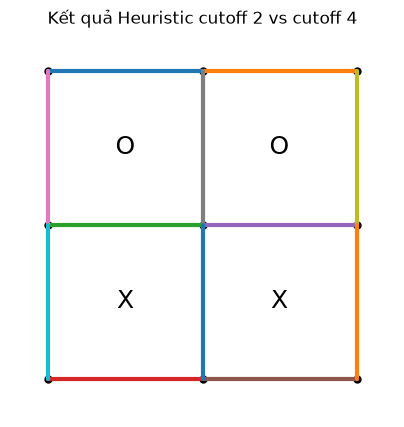

In [92]:

h2=heuristic_player(2); h4=heuristic_player(4)
game_out,final_board=play_game(h2,h4,(3,3),seed=2026)
print("Kết quả (+1 thắng / -1 thắng / 0 hòa):",game_out)
print("Điểm X/O:",score(final_board,1))
fig,ax=plt.subplots(figsize=(5,5)); draw_board(final_board,ax); ax.set_title("Kết quả Heuristic cutoff 2 vs cutoff 4"); plt.show()


## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (PMCS) and investigate its action estimates on the same three manually created states used in Task 3. For each legal action, use the same number of random rollouts; the estimated value is the average terminal utility from the current player's perspective. The rollout must respect the Dots and Boxes extra-turn rule. The following section also applies PMCS to the empty standard 5×5-dot board.

In [93]:
def pmcs_search(state, player=1, rollouts_per_action=100, seed=2026):
    """Pure Monte Carlo Search: equal rollout budget for every legal action."""
    if not isinstance(rollouts_per_action, int) or rollouts_per_action <= 0:
        raise ValueError("rollouts_per_action must be a positive integer")

    legal_actions = actions(state)
    if not legal_actions:
        return None, {}

    rng = random.Random(seed)
    action_values = {}

    for action in legal_actions:
        rewards = []
        for _ in range(rollouts_per_action):
            rollout_state = result(state, action, player)
            to_move = next_player(state, rollout_state, player)

            while not terminal(rollout_state):
                rollout_action = rng.choice(actions(rollout_state))
                next_state = result(rollout_state, rollout_action, to_move)
                to_move = next_player(rollout_state, next_state, to_move)
                rollout_state = next_state

            rewards.append(utility(rollout_state, player))

        action_values[action] = float(np.mean(rewards))

    best_action = max(action_values, key=action_values.get)
    return best_action, action_values


# Run PMCS on the same three manual states used for the minimax tests.
pmcs_manual_rows = []
for state_index, (state_name, state, player) in enumerate(manual):
    best_action, action_values = pmcs_search(
        state, player=player, rollouts_per_action=100,
        seed=2026 + state_index
    )
    for action, estimated_utility in action_values.items():
        pmcs_manual_rows.append({
            "Trạng thái": state_name,
            "Người chơi": player,
            "Nước đi": str(action),
            "Utility trung bình": round(estimated_utility, 4),
            "Rollout mỗi nước": 100,
            "Được PMCS chọn": action == best_action
        })

pmcs_manual_df = pd.DataFrame(pmcs_manual_rows)
display(pmcs_manual_df)


def pmcs_first_move(size=(5,5), rollouts_per_action=100, seed=2026):
    """Estimate the best opening action by PMCS on an empty board."""
    return pmcs_search(
        new_board(size), player=1,
        rollouts_per_action=rollouts_per_action, seed=seed
    )

best_move, opening_scores = pmcs_first_move((5,5), rollouts_per_action=100, seed=2026)
print("Best first move (ước lượng rollout):", best_move)
display(pd.DataFrame([
    {"Nước đi": str(action), "Utility trung bình": value}
    for action, value in opening_scores.items()
]).sort_values("Utility trung bình", ascending=False).head(10))

,Trạng thái,Người chơi,Nước đi,Utility trung bình,Rollout mỗi nước,Được PMCS chọn
0,Có thể ăn ô cuối,-1,"('v', 0, 1)",1.00,100,True
1,Trạng thái 2 ô,1,"('h', 0, 1)",0.14,100,False
2,Trạng thái 2 ô,1,"('h', 1, 1)",-0.34,100,False
3,Trạng thái 2 ô,1,"('v', 0, 1)",2.00,100,True
4,Trạng thái 2 ô,1,"('v', 0, 2)",0.12,100,False
5,Bàn 3x3 gần cuối,-1,"('h', 2, 0)",1.14,100,False
6,Bàn 3x3 gần cuối,-1,"('h', 2, 1)",1.40,100,False
7,Bàn 3x3 gần cuối,-1,"('v', 1, 0)",1.54,100,False
8,Bàn 3x3 gần cuối,-1,"('v', 1, 1)",0.68,100,False
9,Bàn 3x3 gần cuối,-1,"('v', 1, 2)",1.64,100,True


Best first move (ước lượng rollout): ('v', 1, 4)


,Nước đi,Utility trung bình
29,"('v', 1, 4)",2.34
13,"('h', 3, 1)",2.06
12,"('h', 3, 0)",1.68
26,"('v', 1, 1)",1.54
11,"('h', 2, 3)",1.50
18,"('h', 4, 2)",1.44
31,"('v', 2, 1)",1.30
24,"('v', 0, 4)",1.30
1,"('h', 0, 1)",1.28
21,"('v', 0, 1)",1.06


### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [94]:

# Best first move on the standard 5x5-dot board using Pure Monte Carlo Search.
best_move,opening_scores=pmcs_first_move((5,5),rollouts_per_action=100,seed=2026)
print("Best first move (Monte Carlo estimate):",best_move)
opening_df=pd.DataFrame([{"Nước đi":str(k),"Utility trung bình":v} for k,v in opening_scores.items()])
display(opening_df.sort_values("Utility trung bình",ascending=False).head(10))
print("Lưu ý: các vị trí đối xứng có thể có giá trị gần nhau; 100 rollout/action chỉ cho ước lượng, không phải chứng minh tối ưu.")


Best first move (Monte Carlo estimate): ('v', 1, 4)


,Nước đi,Utility trung bình
29,"('v', 1, 4)",2.34
13,"('h', 3, 1)",2.06
12,"('h', 3, 0)",1.68
26,"('v', 1, 1)",1.54
11,"('h', 2, 3)",1.50
18,"('h', 4, 2)",1.44
31,"('v', 2, 1)",1.30
24,"('v', 0, 4)",1.30
1,"('h', 0, 1)",1.28
21,"('v', 0, 1)",1.06


Lưu ý: các vị trí đối xứng có thể có giá trị gần nhau; 100 rollout/action chỉ cho ước lượng, không phải chứng minh tối ưu.


## Tổng kết và nhận xét

Số cấu hình có/không của các cạnh là `2^E`; đây không phải số trạng thái đầy đủ vì quyền sở hữu ô và lượt đi còn phụ thuộc thứ tự đặt cạnh. Với B ô, một cận trên rất lỏng cho bộ mã hóa đầy đủ là `2 × 2^E × 3^B`. Game tree đếm cả thứ tự đặt cạnh nên được chặn trên bởi `Σ P(E,k)`, k=0..E. Alpha-beta pruning không làm thay đổi kết quả minimax nhưng có thể giảm số nút; move ordering tốt (ăn ô trước, nước an toàn kế tiếp, tránh tạo cạnh thứ ba cuối cùng) giúp tăng hiệu quả cắt tỉa. Heuristic cutoff cho phép tìm kiếm trên bàn lớn hơn nhưng kết quả chỉ là xấp xỉ vì đánh giá trạng thái chưa kết thúc. Pure Monte Carlo Search ước lượng nước mở đầu bằng rollout ngẫu nhiên; kết quả phụ thuộc seed và số rollout.

In [95]:
# Task 4 bổ sung: heuristic thứ hai, khác với heuristic gốc.
def heuristic_advanced(s, root_player, to_move):
    """
    Heuristic 2:
    - score_diff: chênh lệch số ô đã sở hữu.
    - urgent: số ô chưa sở hữu có 3 cạnh (có thể ăn ngay).
    - two_edge: số ô chưa sở hữu có 2 cạnh (tín hiệu chiến thuật).
    """
    root_score, opponent_score = score(s, root_player)
    score_diff = root_score - opponent_score

    urgent = 0
    two_edge = 0
    R, C = s["size"]

    for r in range(R - 1):
        for c in range(C - 1):
            box = (r, c)
            if box in s["boxes"]:
                continue

            edge_count = len(box_edges(r, c) & s["lines"].keys())
            if edge_count == 3:
                urgent += 1
            elif edge_count == 2:
                two_edge += 1

    tempo = 1 if to_move == root_player else -1

    # Different weighting from the original heuristic(s).
    return float(score_diff + tempo * (0.75 * urgent + 0.12 * two_edge))


def minimax_alpha_beta_custom(
    s, player=1, depth=4, move_ordering=True, eval_fn=heuristic_advanced
):
    """Alpha-Beta with configurable cutoff evaluation; extra turn is preserved."""
    stats = {"nodes": 0, "leaves": 0, "prunes": 0}
    root = player

    def rec(state, to_move, current_depth, alpha, beta):
        stats["nodes"] += 1

        if terminal(state):
            stats["leaves"] += 1
            return float(utility(state, root)), None

        if depth is not None and current_depth >= depth:
            stats["leaves"] += 1
            return float(eval_fn(state, root, to_move)), None

        maximizing = (to_move == root)
        best_value = -math.inf if maximizing else math.inf
        best_action = None

        for action in ordered_actions(state, to_move, move_ordering):
            next_state = result(state, action, to_move)
            next_to_move = next_player(state, next_state, to_move)

            value, _ = rec(
                next_state, next_to_move, current_depth + 1, alpha, beta
            )

            if maximizing and value > best_value:
                best_value, best_action = value, action
            elif not maximizing and value < best_value:
                best_value, best_action = value, action

            if maximizing:
                alpha = max(alpha, best_value)
            else:
                beta = min(beta, best_value)

            if alpha >= beta:
                stats["prunes"] += 1
                break

        return best_value, best_action

    start = time.perf_counter()
    value, move = rec(s, player, 0, -math.inf, math.inf)
    elapsed = time.perf_counter() - start

    return {
        "move": move,
        "value": value,
        "nodes": stats["nodes"],
        "leaves": stats["leaves"],
        "prunes": stats["prunes"],
        "time_s": elapsed
    }


def advanced_heuristic_player(depth=4):
    def agent(s, player=1):
        return minimax_alpha_beta_custom(
            s, player=player, depth=depth,
            move_ordering=True, eval_fn=heuristic_advanced
        )["move"]
    return agent


# Explicitly distinct agents:
# Agent A: original heuristic, cutoff=2.
# Agent B: advanced heuristic, cutoff=4.
original_h2_agent = heuristic_player(depth=2)
advanced_h4_agent = advanced_heuristic_player(depth=4)

print("Heuristic 1: original heuristic, cutoff=2")
print("Heuristic 2: advanced heuristic, cutoff=4")


Heuristic 1: original heuristic, cutoff=2
Heuristic 2: advanced heuristic, cutoff=4


In [96]:
# Compare the two evaluation functions on the same manually-created states.
heuristic_comparison_rows = []

for state_name, state, player in manual:
    for label, eval_fn in [
        ("Original heuristic", heuristic),
        ("Advanced heuristic", heuristic_advanced)
    ]:
        t0 = time.perf_counter()
        value = eval_fn(state, player, player)
        elapsed = time.perf_counter() - t0

        heuristic_comparison_rows.append({
            "Trạng thái": state_name,
            "Hàm đánh giá": label,
            "Player": player,
            "Giá trị heuristic": round(float(value), 4),
            "Thời gian (ms)": round(elapsed * 1000, 4)
        })

heuristic_comparison_df = pd.DataFrame(heuristic_comparison_rows)
display(heuristic_comparison_df)

# Compare search cost using original vs advanced heuristic at matching cutoffs.
custom_benchmark_rows = []
for size in [(2, 3), (3, 3), (3, 4), (4, 4)]:
    state = new_board(size)
    configurations = [
        ("Original, cutoff=2", 2, heuristic),
        ("Advanced, cutoff=4", 4, heuristic_advanced)
    ]
    if size == (4, 4):
        configurations = [("Original, cutoff=2", 2, heuristic)]
    for label, depth, eval_fn in configurations:
        out = minimax_alpha_beta_custom(
            state, player=1, depth=depth,
            move_ordering=True, eval_fn=eval_fn
        )
        custom_benchmark_rows.append({
            "Kích thước điểm": str(size),
            "Agent": label,
            "Cutoff": depth,
            "Nước đi": out["move"],
            "Giá trị": round(out["value"], 4),
            "Số nút": out["nodes"],
            "Số lá": out["leaves"],
            "Số lần cắt": out["prunes"],
            "Thời gian (ms)": round(out["time_s"] * 1000, 3)
        })

custom_benchmark_df = pd.DataFrame(custom_benchmark_rows)
display(custom_benchmark_df)


,Trạng thái,Hàm đánh giá,Player,Giá trị heuristic,Thời gian (ms)
0,Có thể ăn ô cuối,Original heuristic,-1,0.20,0.0211
1,Có thể ăn ô cuối,Advanced heuristic,-1,0.75,0.0087
2,Trạng thái 2 ô,Original heuristic,1,0.20,0.0089
3,Trạng thái 2 ô,Advanced heuristic,1,0.75,0.0070
4,Bàn 3x3 gần cuối,Original heuristic,-1,2.00,0.0117
5,Bàn 3x3 gần cuối,Advanced heuristic,-1,2.00,0.0052


,Kích thước điểm,Agent,Cutoff,Nước đi,Giá trị,Số nút,Số lá,Số lần cắt,Thời gian (ms)
0,"(2, 3)","Original, cutoff=2",2,"(h, 0, 0)",0.00,20,12,6,0.667
1,"(2, 3)","Advanced, cutoff=4",4,"(v, 0, 1)",0.87,202,111,62,5.158
2,"(3, 3)","Original, cutoff=2",2,"(h, 0, 0)",0.00,35,22,11,2.005
3,"(3, 3)","Advanced, cutoff=4",4,"(h, 1, 0)",0.24,687,463,175,31.775
4,"(3, 4)","Original, cutoff=2",2,"(h, 0, 0)",0.00,50,32,16,4.514
5,"(3, 4)","Advanced, cutoff=4",4,"(h, 1, 1)",0.24,1804,1239,491,114.202
6,"(4, 4)","Original, cutoff=2",2,"(h, 0, 0)",0.00,71,46,23,9.040


In [97]:
# Tournament: different cutoff depth AND different heuristic function.
# 30 games per seat assignment (60 games total) on a 3x3-dot board.
def play_heuristic_match(agent1, agent2, games_per_side=30, size=(3, 3), seed=2026):
    rows = []

    for agent1_side in [1, -1]:
        counts = Counter()

        for game_index in range(games_per_side):
            game_seed = seed + (0 if agent1_side == 1 else 10000) + game_index

            if agent1_side == 1:
                winner, final_state = play_game(
                    agent1, agent2, size=size, seed=game_seed
                )
                agent1_won = winner == 1
            else:
                winner, final_state = play_game(
                    agent2, agent1, size=size, seed=game_seed
                )
                agent1_won = winner == -1

            if winner == 0:
                counts["draw"] += 1
            elif agent1_won:
                counts["agent1"] += 1
            else:
                counts["agent2"] += 1

        rows.append({
            "Agent 1": "Original heuristic, cutoff=2",
            "Agent 2": "Advanced heuristic, cutoff=4",
            "Agent 1 position": "+1 (đi trước)" if agent1_side == 1 else "-1 (đi sau)",
            "Agent 1 wins": counts["agent1"],
            "Agent 2 wins": counts["agent2"],
            "Draws": counts["draw"],
            "Games": games_per_side
        })

    return pd.DataFrame(rows)


heuristic_match_df = play_heuristic_match(
    original_h2_agent,
    advanced_h4_agent,
    games_per_side=30,
    size=(3, 3),
    seed=2026
)

display(heuristic_match_df)


,Agent 1,Agent 2,Agent 1 position,Agent 1 wins,Agent 2 wins,Draws,Games
0,"Original heuristic, cutoff=2","Advanced heuristic, cutoff=4",+1 (đi trước),0,0,30,30
1,"Original heuristic, cutoff=2","Advanced heuristic, cutoff=4",-1 (đi sau),0,30,0,30


In [98]:
import os

# Tạo thư mục result tại thư mục làm việc hiện tại của notebook.
RESULT_DIR = "result"
os.makedirs(RESULT_DIR, exist_ok=True)

# Các DataFrame đã được tạo ở những cell thí nghiệm phía trên.
# Giữ đúng tên biến trong notebook, đặc biệt là pmcs_manual_df.
csv_files = {
    "dots_heuristic_agents_tournament.csv": heuristic_match_df,
    "dots_heuristic_function_comparison.csv": heuristic_comparison_df,
    "dots_custom_heuristic_benchmark.csv": custom_benchmark_df,
    "dots_pmcs_manual_state_tests.csv": pmcs_manual_df,
    "dots_pmcs_best_first_move_5x5.csv": opening_df,
}

# Kiểm tra trước khi lưu để báo lỗi rõ ràng nếu thiếu DataFrame.
for filename, df in csv_files.items():
    if not isinstance(df, pd.DataFrame):
        raise TypeError(f"{filename}: dữ liệu phải là pandas DataFrame")

for filename, df in csv_files.items():
    filepath = os.path.join(RESULT_DIR, filename)
    df.to_csv(filepath, index=False, encoding="utf-8-sig")
    print(f"Đã lưu: {filepath} | {len(df)} dòng × {len(df.columns)} cột")

print("\nHoàn tất lưu toàn bộ kết quả CSV!")
print("Thư mục lưu:", os.path.abspath(RESULT_DIR))

Đã lưu: result\dots_heuristic_agents_tournament.csv | 2 dòng × 7 cột
Đã lưu: result\dots_heuristic_function_comparison.csv | 6 dòng × 5 cột
Đã lưu: result\dots_custom_heuristic_benchmark.csv | 7 dòng × 9 cột
Đã lưu: result\dots_pmcs_manual_state_tests.csv | 10 dòng × 6 cột
Đã lưu: result\dots_pmcs_best_first_move_5x5.csv | 40 dòng × 2 cột

Hoàn tất lưu toàn bộ kết quả CSV!
Thư mục lưu: f:\TTNTNC\LAB05_GAME\result


In [99]:
# ĐÁNH GIÁ CHUẨN HÓA: mỗi tác tử đấu Random 200 ván (100 +1, 100 -1).
# Đo riêng thời gian agent suy nghĩ; PMCS ghi nhận N=10, 100, 1000.
import time, random, os
import pandas as pd
from collections import Counter

def make_pmcs_agent(rollouts):
    call_seed = {"value": 0}
    def agent(state, player=1):
        call_seed["value"] += 1
        action, _ = pmcs_search(
            state, player=player, rollouts_per_action=rollouts,
            seed=20261112 + call_seed["value"]
        )
        return action
    agent.__name__ = f"PMCS_N{rollouts}"
    return agent

def run_dots_standard_tournament(agent, agent_name, size=(2,3), games_per_side=100, seed=20261112):
    rows = []
    total_time = 0.0
    total_moves = 0
    total_wins = total_draws = total_losses = 0

    for agent_first in (True, False):
        counts = Counter()
        side_time = 0.0
        side_moves = 0
        for game_idx in range(games_per_side):
            game_seed = seed + (0 if agent_first else 100000) + game_idx
            random.seed(game_seed)
            state = new_board(size)
            player = 1
            while not terminal(state):
                is_agent_turn = (player == 1) == agent_first
                if is_agent_turn:
                    t0 = time.perf_counter()
                    action = agent(state, player)
                    side_time += time.perf_counter() - t0
                    side_moves += 1
                else:
                    action = random_player(state, player)
                next_state = result(state, action, player)
                player = next_player(state, next_state, player)
                state = next_state

            x_score, o_score = score(state, 1)
            winner = 1 if x_score > o_score else -1 if o_score > x_score else 0
            agent_side = 1 if agent_first else -1
            if winner == 0: counts["draw"] += 1
            elif winner == agent_side: counts["win"] += 1
            else: counts["loss"] += 1

        total_time += side_time
        total_moves += side_moves
        total_wins += counts["win"]
        total_draws += counts["draw"]
        total_losses += counts["loss"]
        rows.append({
            "Agent": agent_name,
            "Vị trí": "+1 (đi trước)" if agent_first else "-1 (đi sau)",
            "Thắng": counts["win"], "Hòa": counts["draw"], "Thua": counts["loss"],
            "Số ván": games_per_side,
            "Tổng thời gian agent (ms)": round(side_time * 1000, 4),
            "Số nước agent": side_moves,
            "Thời gian TB/nước (ms)": round(side_time * 1000 / side_moves, 6) if side_moves else 0
        })

    summary = {
        "Agent": agent_name, "Thắng": total_wins, "Hòa": total_draws, "Thua": total_losses,
        "Tổng số ván": 2 * games_per_side,
        "Tổng thời gian agent (ms)": round(total_time * 1000, 4),
        "Tổng số nước agent": total_moves,
        "Thời gian TB/nước (ms)": round(total_time * 1000 / total_moves, 6) if total_moves else 0
    }
    return pd.DataFrame(rows), summary

dots_standard_agents = [
    ("Minimax Alpha-Beta", minimax_player),
    ("Heuristic cutoff=2", heuristic_player(depth=2)),
    ("Heuristic cutoff=4", heuristic_player(depth=4)),
    ("PMCS N=10", make_pmcs_agent(10)),
    ("PMCS N=100", make_pmcs_agent(100)),
    ("PMCS N=1000", make_pmcs_agent(1000)),
]

dots_standard_details = []
dots_standard_summaries = []
for idx, (agent_name, agent_fn) in enumerate(dots_standard_agents):
    detail, summary = run_dots_standard_tournament(
        agent_fn, agent_name, size=(2,3), seed=20261112 + idx * 10000
    )
    dots_standard_details.append(detail)
    dots_standard_summaries.append(summary)

dots_standard_detail_df = pd.concat(dots_standard_details, ignore_index=True)
dots_standard_summary_df = pd.DataFrame(dots_standard_summaries)
display(dots_standard_detail_df)
display(dots_standard_summary_df)

os.makedirs("result", exist_ok=True)
dots_standard_detail_df.to_csv("result/dots_standard_tournament_detail.csv", index=False, encoding="utf-8-sig")
dots_standard_summary_df.to_csv("result/dots_standard_tournament_summary.csv", index=False, encoding="utf-8-sig")


KeyboardInterrupt: 